<a href="https://colab.research.google.com/github/vyakhyaagoyal/DL_Lab_V/blob/main/vyakhya_Speech_Emotion_Recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
# !pip install librosa

In [17]:
# !pip install tensorflow

In [18]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import librosa
import librosa.display
import matplotlib.pyplot as plt
from IPython.display import Audio
import warnings
warnings.filterwarnings('ignore')

In [27]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [33]:
import os

path = "/content/drive/MyDrive/archive/TESS Toronto emotional speech set data"

print("Folder exists:", os.path.exists(path))

if os.path.exists(path):
    print(os.listdir(path)[:20])
print("Total audio files:", len(all_images))
print("Total labels:", len(labels))
print("First audio file:", all_images[0] if all_images else "No files found")

Folder exists: True
['YAF_fear', 'YAF_angry', 'OAF_Sad', 'YAF_sad', 'YAF_disgust', 'OAF_Fear', 'YAF_neutral', 'OAF_Pleasant_surprise', 'YAF_happy', 'YAF_pleasant_surprised', 'OAF_neutral', 'OAF_disgust', 'OAF_happy', 'OAF_angry', 'TESS Toronto emotional speech set data']
Total audio files: 0
Total labels: 0
First audio file: No files found


In [35]:
import os

path = "/content/drive/MyDrive/archive/TESS Toronto emotional speech set data"

all_images = []
labels = []

for root, dirs, files in os.walk(path):
    for f in files:
        if f.lower().endswith(".wav"):
            all_images.append(os.path.join(root, f))

            # Extract emotion from the filename
            label = f.rsplit("-", 1)[-1]
            label = os.path.splitext(label)[0]
            labels.append(label.lower())

print("Total audio files:", len(all_images))
print("Total labels:", len(labels))
print("Sample files:", all_images[:5])
print("Sample labels:", labels[:5])

Total audio files: 5600
Total labels: 5600
Sample files: ['/content/drive/MyDrive/archive/TESS Toronto emotional speech set data/YAF_fear/YAF_match_fear.wav', '/content/drive/MyDrive/archive/TESS Toronto emotional speech set data/YAF_fear/YAF_check_fear.wav', '/content/drive/MyDrive/archive/TESS Toronto emotional speech set data/YAF_fear/YAF_said_fear.wav', '/content/drive/MyDrive/archive/TESS Toronto emotional speech set data/YAF_fear/YAF_soup_fear.wav', '/content/drive/MyDrive/archive/TESS Toronto emotional speech set data/YAF_fear/YAF_shawl_fear.wav']
Sample labels: ['yaf_match_fear', 'yaf_check_fear', 'yaf_said_fear', 'yaf_soup_fear', 'yaf_shawl_fear']


In [36]:
len(all_images)

5600

In [37]:
labels[:5]

['yaf_match_fear',
 'yaf_check_fear',
 'yaf_said_fear',
 'yaf_soup_fear',
 'yaf_shawl_fear']

In [38]:
df = pd.DataFrame()
df['speech'] = all_images
df['label'] = labels
df.head()

,speech,label
0,/content/drive/MyDrive/archive/TESS Toronto em...,yaf_match_fear
1,/content/drive/MyDrive/archive/TESS Toronto em...,yaf_check_fear
2,/content/drive/MyDrive/archive/TESS Toronto em...,yaf_said_fear
3,/content/drive/MyDrive/archive/TESS Toronto em...,yaf_soup_fear
4,/content/drive/MyDrive/archive/TESS Toronto em...,yaf_shawl_fear


In [39]:
df['label'].value_counts()

,count
label,
oaf_young_angry,2
oaf_rose_angry,2
oaf_size_angry,2
oaf_team_angry,2
oaf_thumb_angry,2
...,...
yaf_shawl_fear,2
yaf_soup_fear,2
yaf_said_fear,2


# Explorartory Data Analysis

<Figure size 800x800 with 0 Axes>

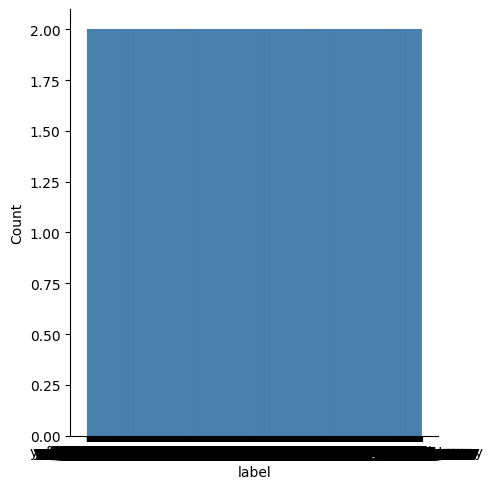

In [40]:
plt.figure(figsize = [8, 8])
sns.displot(df['label'])

In [41]:
import librosa.display
def waveplot(data, sr, emotion):
    plt.figure(figsize = [10, 8])
    plt.title(emotion, size = 20)
    librosa.display.waveshow(data, sr = sr)
    plt.show()

def spectogram(data, sr, emotion):
    x = librosa.stft(data)
    xdb = librosa.amplitude_to_db(abs(x))
    plt.figure(figsize = [11, 4])
    plt.title(emotion, size = 20)
    librosa.display.specshow(xdb, sr = sr, x_axis = 'time', y_axis = 'hz')
    plt.colorbar()

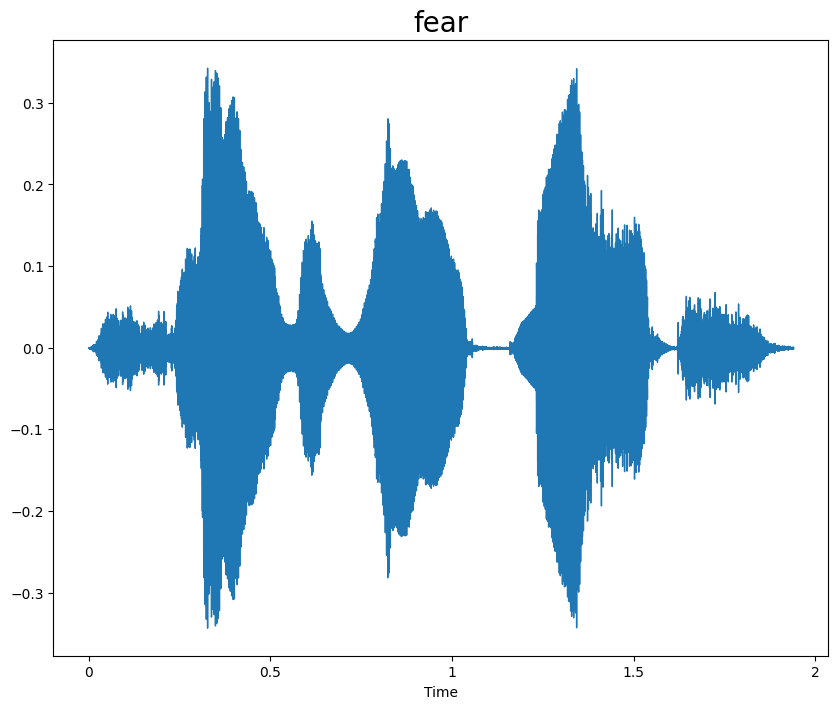

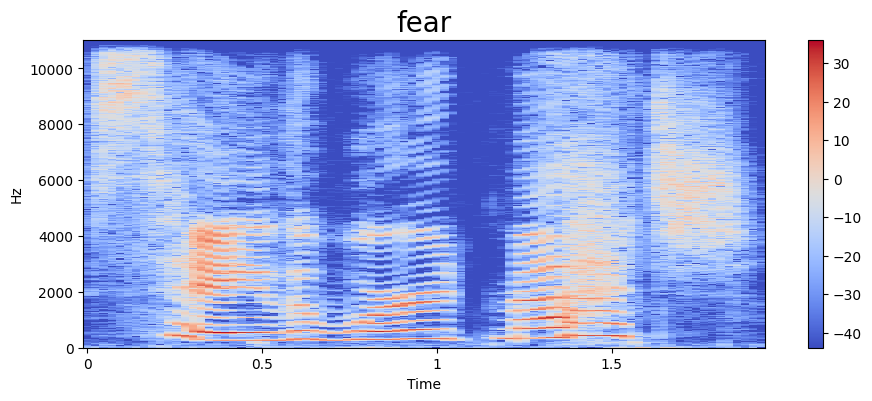

In [44]:
emotion = 'fear'
# Use .str.contains to find labels containing the substring 'fear'
path = np.array(df['speech'][df['label'].str.contains(emotion)])[0]
data, sampling_rate = librosa.load(path)
waveplot(data, sampling_rate, emotion)
spectogram(data, sampling_rate, emotion)
Audio(path)

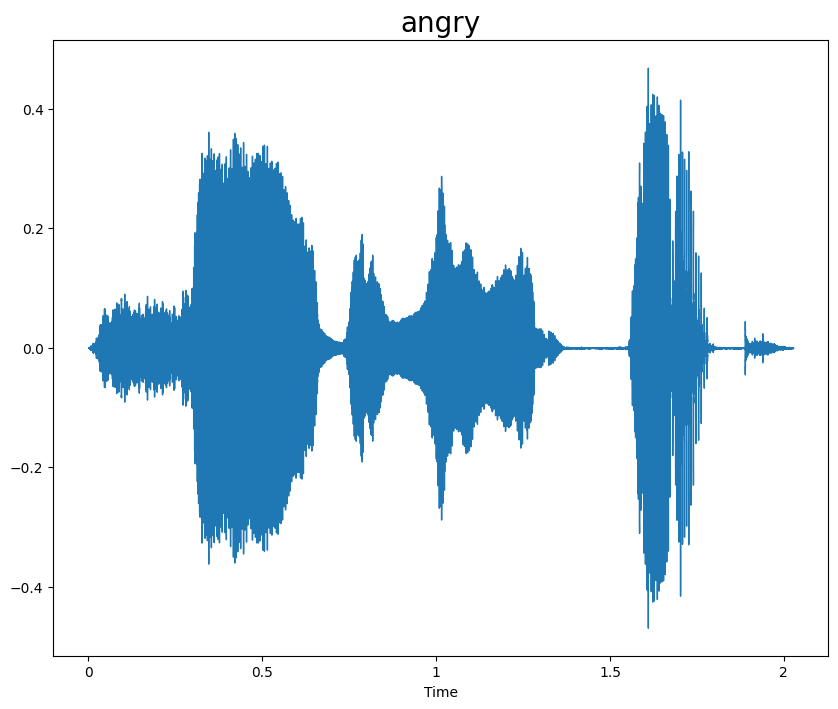

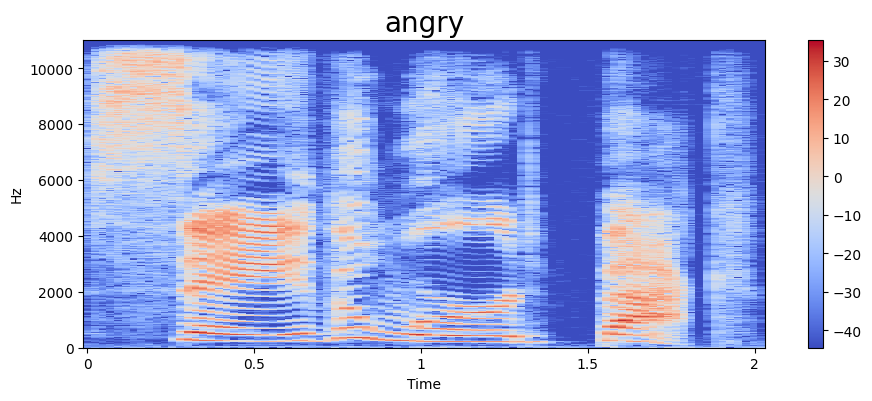

In [47]:
emotion = 'angry'
# Use .str.contains to find labels containing 'angry'
path = np.array(df['speech'][df['label'].str.contains(emotion)])[5]
data, sampling_rate = librosa.load(path)
waveplot(data, sampling_rate, emotion)
spectogram(data, sampling_rate, emotion)
Audio(path)

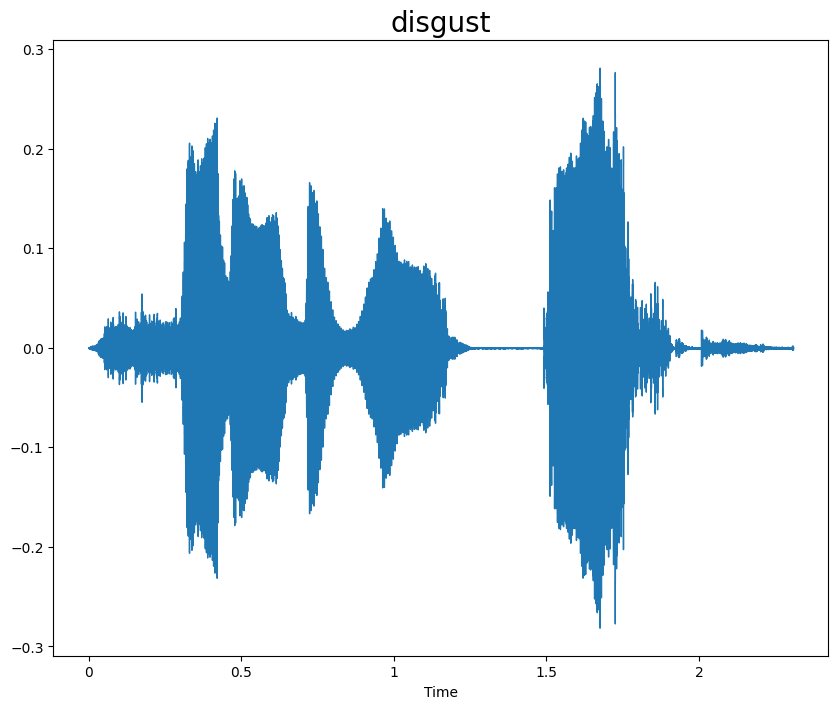

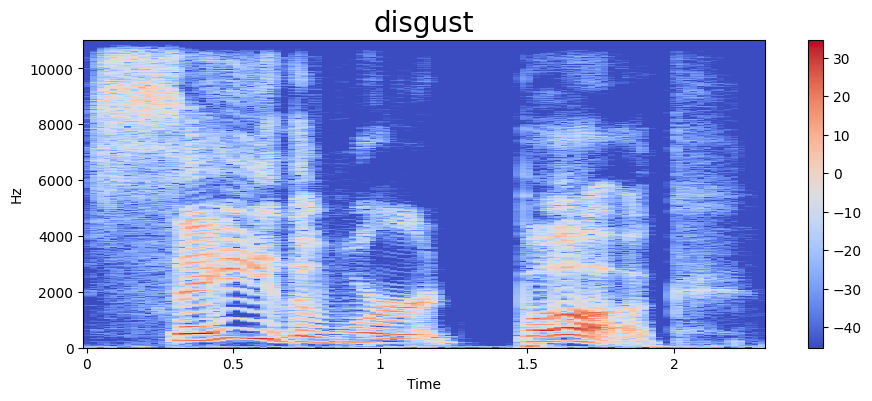

In [49]:
emotion = 'disgust'
# Use .str.contains to find labels containing 'disgust'
path = np.array(df['speech'][df['label'].str.contains(emotion)])[8]
data, sampling_rate = librosa.load(path)
waveplot(data, sampling_rate, emotion)
spectogram(data, sampling_rate, emotion)
Audio(path)

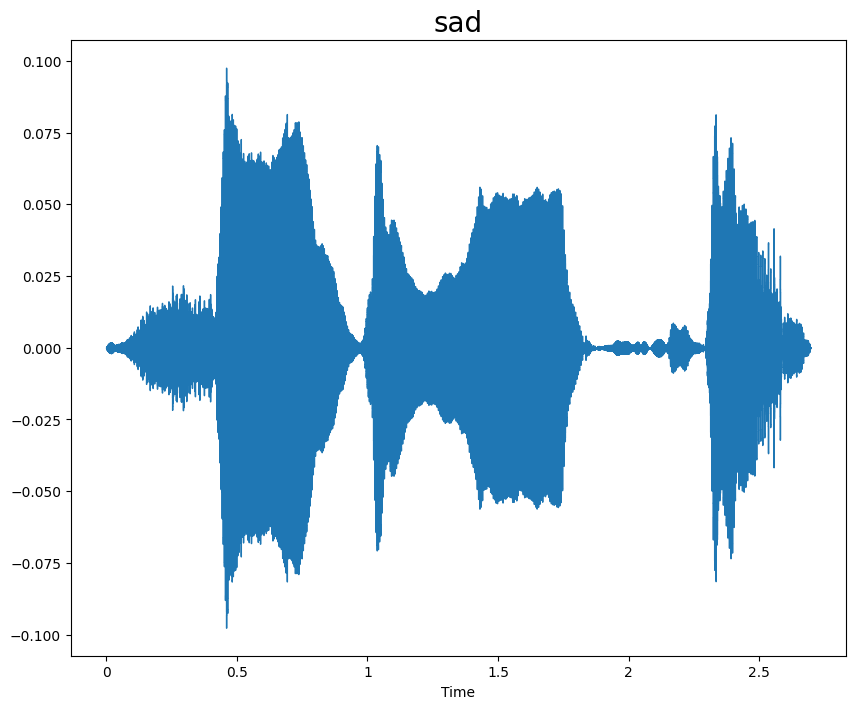

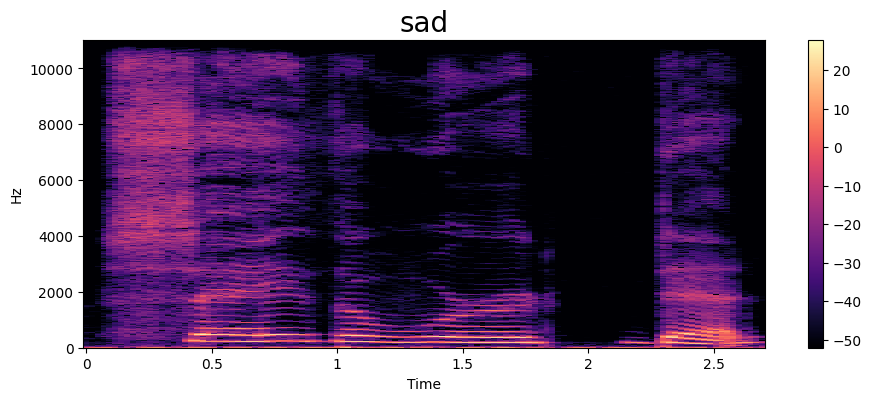

In [51]:
emotion = 'sad'
# Use .str.contains to find labels containing the substring 'sad'
path = np.array(df['speech'][df['label'].str.contains(emotion)])[6]
data, sampling_rate = librosa.load(path)
waveplot(data, sampling_rate, emotion)
spectogram(data, sampling_rate, emotion)
Audio(path)

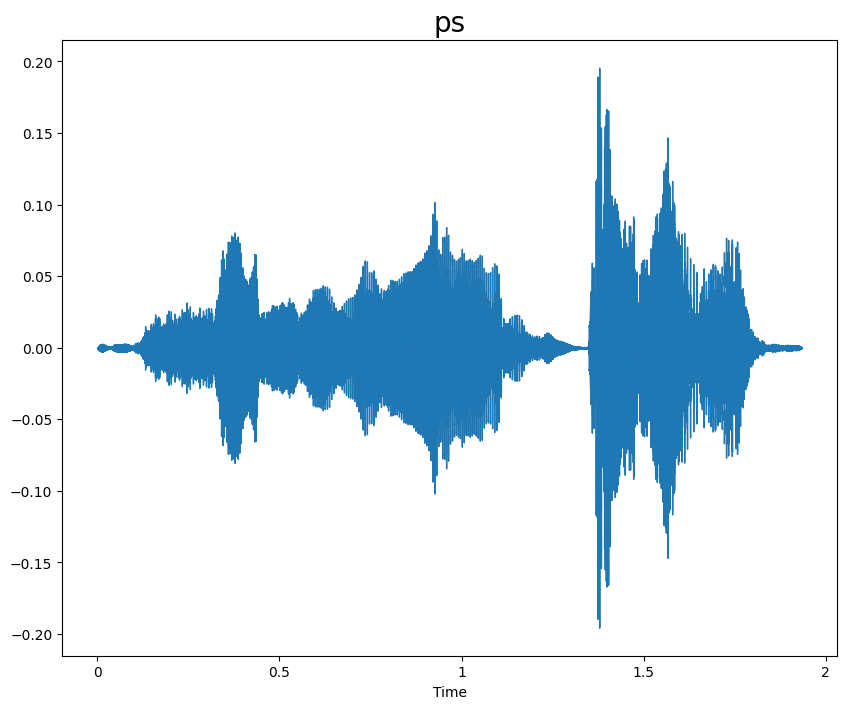

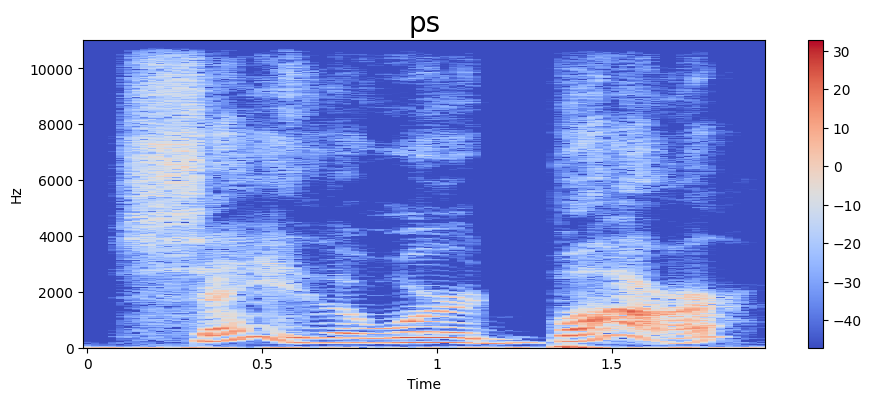

In [53]:
emotion = 'ps'
# Use .str.contains to find labels containing the substring 'ps'
path = np.array(df['speech'][df['label'].str.contains(emotion)])[1]
data, sampling_rate = librosa.load(path)
waveplot(data, sampling_rate, emotion)
spectogram(data, sampling_rate, emotion)
Audio(path)

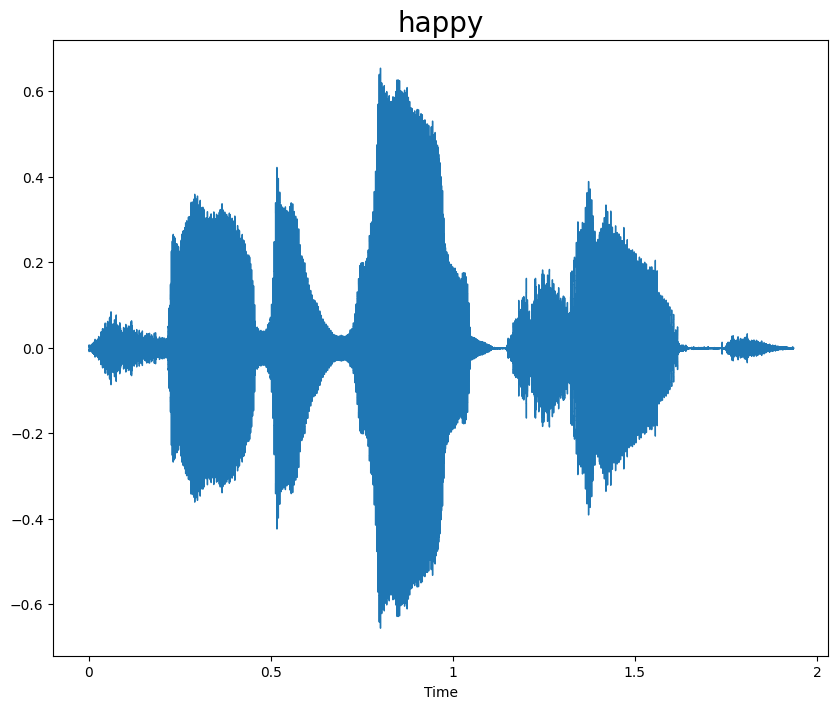

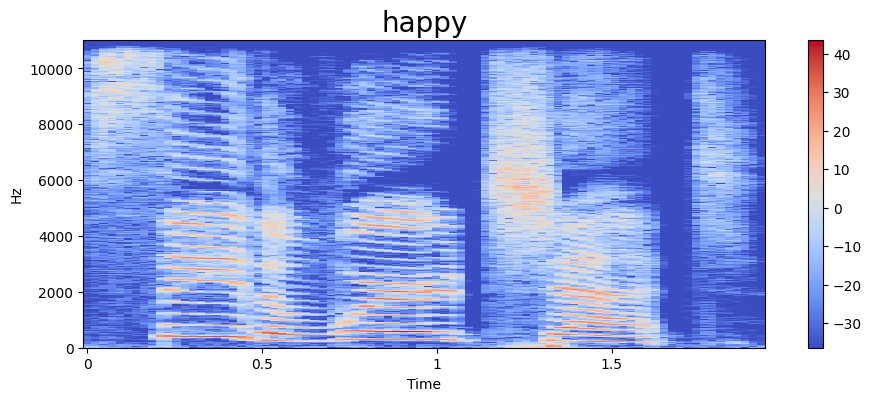

In [55]:
emotion = 'happy'
# Use .str.contains to find labels containing the substring 'happy'
path = np.array(df['speech'][df['label'].str.contains(emotion)])[0]
data, sampling_rate = librosa.load(path)
waveplot(data, sampling_rate, emotion)
spectogram(data, sampling_rate, emotion)
Audio(path)

# Feature extraction

In [56]:
def extract_mfcc(filename):
    y, sr = librosa.load(filename, duration = 3, offset = 0.5)
    mfcc = np.mean(librosa.feature.mfcc(y = y, sr = sr, n_mfcc = 40).T, axis = 0)
    return mfcc

In [57]:
extract_mfcc(df['speech'][0])

array([-3.35683868e+02,  3.64425507e+01, -2.38812523e+01,  1.40019436e+01,
       -1.34373913e+01,  5.50049114e+00, -3.39709711e+00, -1.29085760e+01,
       -7.25439835e+00,  4.24938536e+00, -1.23111219e+01,  2.81311154e-01,
       -2.78014827e+00, -6.57956004e-01,  4.68815422e+00, -3.80830288e+00,
       -1.38505244e+00,  9.72235489e+00, -8.13756847e+00,  3.68150878e+00,
        9.12196541e+00,  1.15423374e+01,  1.09987955e+01,  1.30143251e+01,
        2.65415812e+00,  6.19905567e+00,  8.04706570e-03,  2.86827087e+00,
       -4.89872813e-01, -1.93162835e+00, -4.99335527e+00,  2.46706295e+00,
       -2.32088256e+00, -9.06995595e-01, -5.28235912e+00, -2.94692373e+00,
       -8.20944726e-01, -8.18626046e-01, -2.77127767e+00,  2.85868621e+00],
      dtype=float32)

In [58]:
# def compute_spectrogram(audio_file, n_fft=2048, hop_length=512, sr=22050):
#     # load audio data
#     y, sr = librosa.load(audio_file, sr=sr)

#     # compute spectrogram
#     spec = librosa.stft(y, n_fft=n_fft, hop_length=hop_length)
#     spec_db = librosa.amplitude_to_db(abs(spec))

#     return spec_db, sr

# def plot_spectrogram(spec_db, sr, hop_length=512):
#     # visualize spectrogram
#     plt.figure(figsize=(12, 6))
#     librosa.display.specshow(spec_db, sr=sr, hop_length=hop_length, x_axis='time', y_axis='log')
#     plt.colorbar(format='%+2.0f dB')
#     plt.title('Spectrogram')
#     plt.tight_layout()
#     plt.show()

In [59]:
# # compute spectrogram
# spec_db, sr = compute_spectrogram(df['speech'][5])

# # plot spectrogram
# plot_spectrogram(spec_db, sr)

In [60]:
# def extract_chroma_features(audio_file, sr=22050, n_fft=2048, hop_length=512):
#     # Load audio data
#     y, sr = librosa.load(audio_file, sr=sr)

#     # Compute chroma features
#     chroma = librosa.feature.chroma_stft(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length)

#     # Normalize chroma features
#     chroma_norm = librosa.util.normalize(chroma, norm=np.inf, axis=1)

#     return chroma_norm

In [61]:
# # Extract chroma features
# chroma = extract_chroma_features(df['speech'][0])
# chroma

In [ ]:
X_mfcc = df['speech'].apply(lambda x: extract_mfcc(x))

In [ ]:
X = [x for x in X_mfcc]
X = np.array(X)
X.shape

In [ ]:
## input split
X = np.expand_dims(X, -1)
X.shape

In [ ]:
from sklearn.preprocessing import OneHotEncoder
enc = OneHotEncoder()
y = enc.fit_transform(df[['label']])

In [ ]:
y = y.toarray()

# Training LSTM Model

In [ ]:
from keras.models import Sequential
from keras.layers import Dense, LSTM, Dropout
from collections.abc import Iterable

model = Sequential([
    LSTM(256, return_sequences=False, input_shape=(40,1)),
    Dropout(0.2),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(7, activation='softmax')
])

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()
print(Iterable)

In [ ]:
from keras.callbacks import ModelCheckpoint
from keras.callbacks import LearningRateScheduler
import tensorflow as tf

checkpoint_filepath = 'best_model.h5'
model_checkpoint_callback = ModelCheckpoint(
    filepath=checkpoint_filepath,
    save_best_only=True,
    monitor='val_accuracy',
    mode='max',
    verbose=1)


def scheduler(epoch, lr):
    if epoch < 10:
        return lr
    else:
        return lr * tf.math.exp(-0.1)

lr_scheduler_callback = LearningRateScheduler(scheduler)

history = model.fit(X, y, validation_split=0.2, epochs=50, batch_size=64, callbacks=[model_checkpoint_callback, lr_scheduler_callback])

# Plot the results

In [ ]:
epochs = list(range(50))
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

plt.plot(epochs, acc, label='train accuracy')
plt.plot(epochs, val_acc, label='val accuracy')
plt.xlabel('epochs')
plt.ylabel('accuracy')
plt.legend()
plt.show()

In [ ]:
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.plot(epochs, loss, label='train loss')
plt.plot(epochs, val_loss, label='val loss')
plt.xlabel('epochs')
plt.ylabel('loss')
plt.legend()
plt.show()

In [ ]:
import librosa
import numpy as np
from tensorflow.keras.models import load_model

# Load the trained model
model = load_model('best_model.h5')

# Load the new audio file
path_to_audio = 'angry_adio.mp3'
audio, sr = librosa.load(path_to_audio, sr=22050, duration=3, offset=0.5)

# Extract the MFCC features
mfccs = np.mean(librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=40).T, axis=0)

# Reshape the extracted MFCC features to match the input shape of the trained model
mfccs = mfccs.reshape(1, -1)

# Normalize the extracted MFCC features using the same normalization parameters used during training
mean = np.load('mean.npy')
std = np.load('std.npy')
mfccs = (mfccs - mean) / std

# Use the predict() function of the trained model to get the predicted emotion label
prediction = model.predict(mfccs)
emotion_labels = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
predicted_emotion = emotion_labels[np.argmax(prediction)]

print(f'The predicted emotion is: {predicted_emotion}')